In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp  # type: ignore[import]
from pathlib import Path
import matplotlib.pyplot as plt
import time

# --------------------------------- Internal imports --------------------------------- #
from radiopyo_vec.physics.beam import ConstantBeam, ParticleBeam, PulsedBeam
from radiopyo_vec.sim_env import SimEnv
from radiopyo_vec.ode_solver import derive, jac, reconstruct_KRi_from_res
import radiopyo_vec as rp

In [2]:
from Plot_template import RPlot, FigManager
RPlot.init_rcparams()
fig_man = FigManager()

In [3]:
def matprint(mat, fmt="g"):
    col_maxes = [max([len(("{:"+fmt+"}").format(x)) for x in col]) for col in mat.T]
    for x in mat:
        for i, y in enumerate(x):
            print(("{:"+str(col_maxes[i])+fmt+"}").format(y), end="  ")
        print("")

### Prepare Sim Env

In [11]:
file = Path(rf"{rp.__path__[0]}\data\reactions_bio_prot.ron")
beam = ConstantBeam("e", 1000, max_dose=13)
beam = PulsedBeam("e", 1000, max_dose=13, period=0.5, on_time=500e-6)
env = SimEnv.from_ron_file(file)

In [12]:
kwargs = {}
kwargs["max_step"] = np.inf
kwargs["first_step"] = 1e-15
kwargs["atol"] = 1e-10
kwargs["method"] = "LSODA" # Possibilities: ["LSODA", "BDF", "Radau","DOP853","RK45"]
t_span = [1e-9, 150]
tlog = np.arange(-9, -2.9, step=0.1)
tspan = np.power(10, tlog)
tspan = np.append(tspan, np.arange(2e-3, t_span[1], step=1e-3))
y0 = env.initial_values()
ab_mat = env.make_acidBase_matrix()
ki_mat = env.make_kreaction_matrix()
Gi_mat = env.make_radiolytic_vector()
Enzi   = env.make_enzymatic_matrix()

for sp in env.species:
    print(f"{sp.index}) {sp.label} = {y0[sp.index]:.2g}")

0) H2O = 5.5e+07
1) catalase = 0.08
2) Fe_plus_plus = 0.89
3) GSH = 6.5e+03
4) RH = 1e+06
5) unsat_lipid = 1
6) H_plus = 0.1
7) OH_minus = 0.1
8) OH_r = 0
9) O_r_minus = 0
10) H2O2 = 0
11) HO2_minus = 0
12) HO2_r = 0
13) O2_r_minus = 0
14) e_aq = 0
15) H_r = 0
16) H2 = 0
17) O2 = 50
18) O2_minus_minus = 0
19) O3_minus = 0
20) Fe_plus_plus_plus = 0
21) HO_r = 0
22) RH_r = 0
23) R_r = 0
24) ROO_r = 0
25) trash = 0
26) ROH = 0
27) RO = 0
28) ROOH = 0


## Run Sim

In [13]:
print(f"Running simulation at {beam.dose_rate} Gy/s")

t0 = time.time()
sol = solve_ivp(derive, t_span, y0, args=(ab_mat, ki_mat, Gi_mat, beam, Enzi),t_eval=tspan, jac=jac, **kwargs)
t1 = time.time()

sim_t, res = sol.t, sol.y
print(f"\t==> Execution time was {t1-t0:.3f} s")


Running simulation at 1000 Gy/s
	==> Execution time was 7.984 s


## Plot

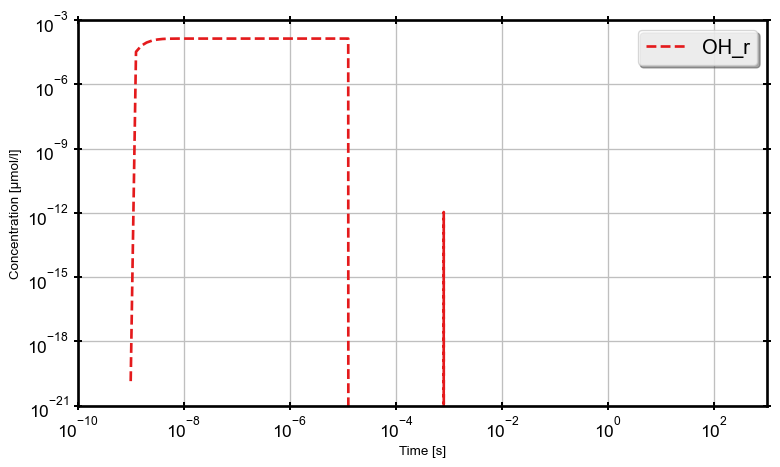

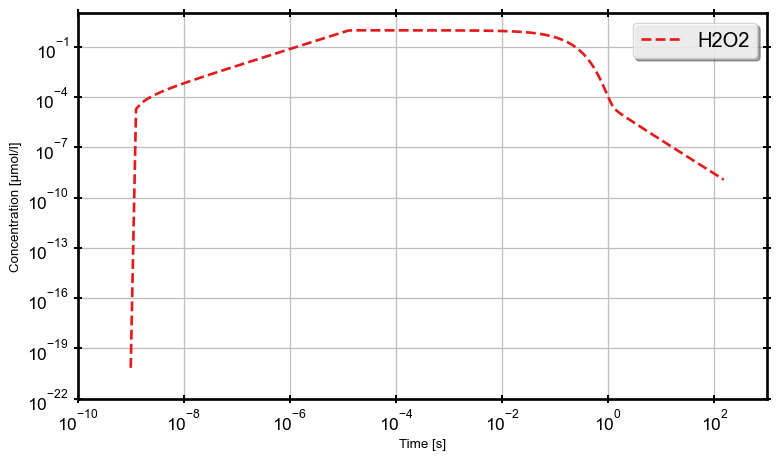

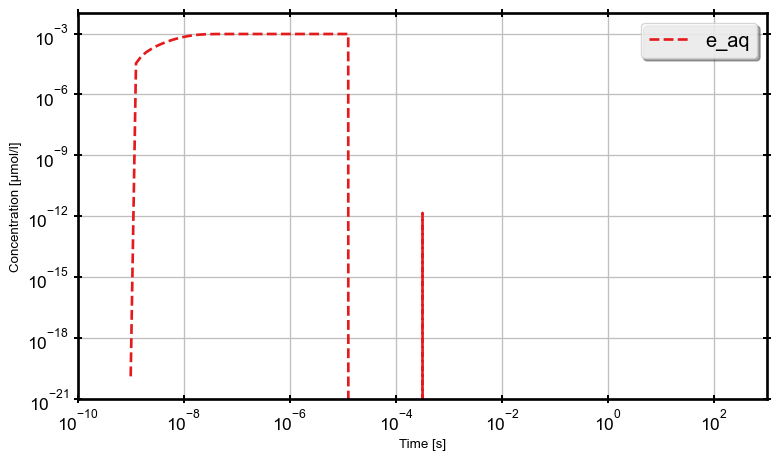

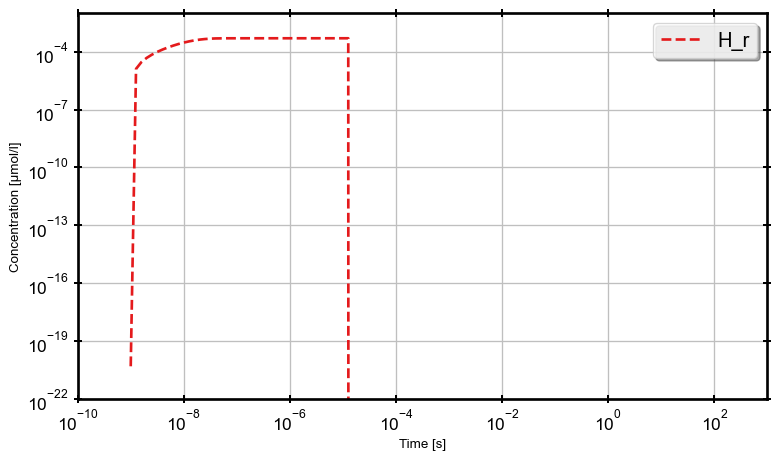

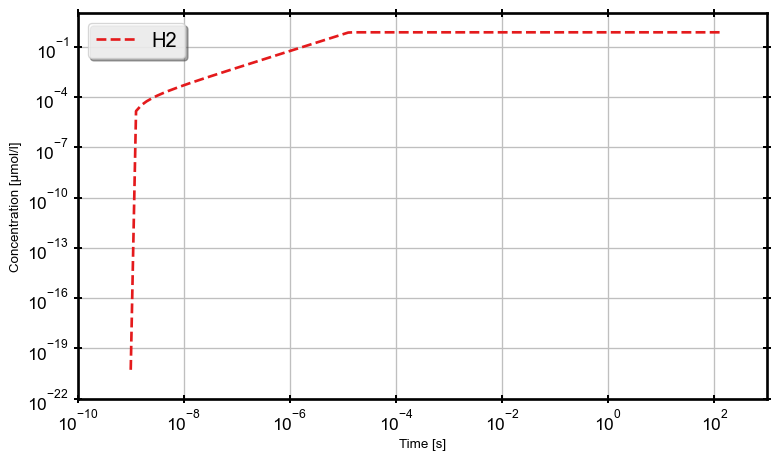

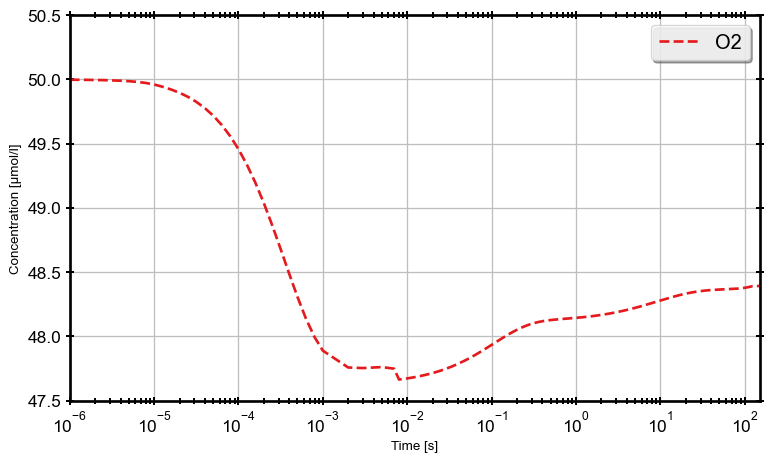

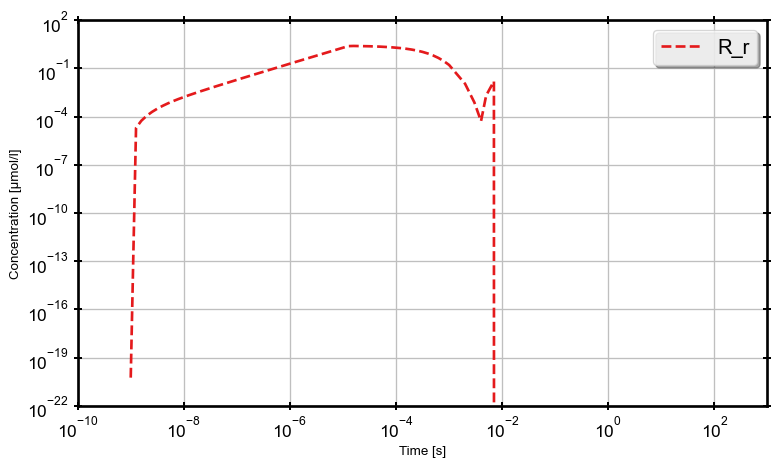

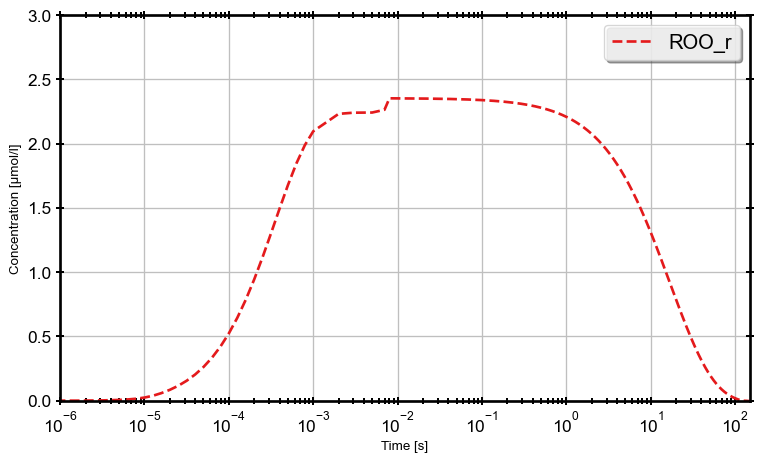

In [14]:
for (label, sp) in zip(env.species_labels(), res):
    if label not in ["OH_r", "H2O2", "e_aq", "H_r", "O2", "H2", "R_r", "ROO_r"]:
        continue
    with fig_man.open(f"{label.replace('/', '_')} CC evolution") as (fig, ax):
        #sp = sp * 1e6
        if label=="O2":
            ax.semilogx(sim_t , sp , label=label, marker="")
            ax.set_xlim([1e-6, 150])
            #ax.set_ylim([49.9, 50.01])
        elif label=="ROO_r":
            ax.semilogx(sim_t, sp, label=label, marker="")
            ax.set_ylim([0, 3])
            ax.set_xlim([1e-6, 150])
        else:
            ax.loglog(sim_t , sp , label=label, marker="")
            #ax.set_ylim(bottom=1e-6, top=4)
        ax.legend(loc='best')
        
        ax.set_xlabel("Time [s]")
        ax.set_ylabel("Concentration [µmol/l]")

## Explore reaction Rates:

In [23]:
df = reconstruct_KRi_from_res(sim_t, res, env, ab_mat, ki_mat, Gi_mat, beam, Enzi) 

In [24]:
df

,KR_0,KR_1,KR_2,KR_3,KR_4,KR_5,KR_6,KR_7,KR_8,KR_9,...,KR_28,KR_29,KR_30,KR_31,KR_32,KR_33,KR_34,KR_35,KR_36,KR_37
1.000000e-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.258925e-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000002,0.00001,0.000004,0.000064,0.0,0.0,0.0,0.0,0.0,0.0
1.584893e-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000004,0.000023,0.000008,0.000126,0.0,0.0,0.0,0.0,0.0,0.0
1.995262e-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000006,0.000038,0.000012,0.000178,0.0,0.0,0.0,0.0,0.0,0.0
2.511886e-09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000009,0.000055,0.000014,0.000217,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9.995000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9.996000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9.997000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9.998000e+00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Plot reaction rates by species

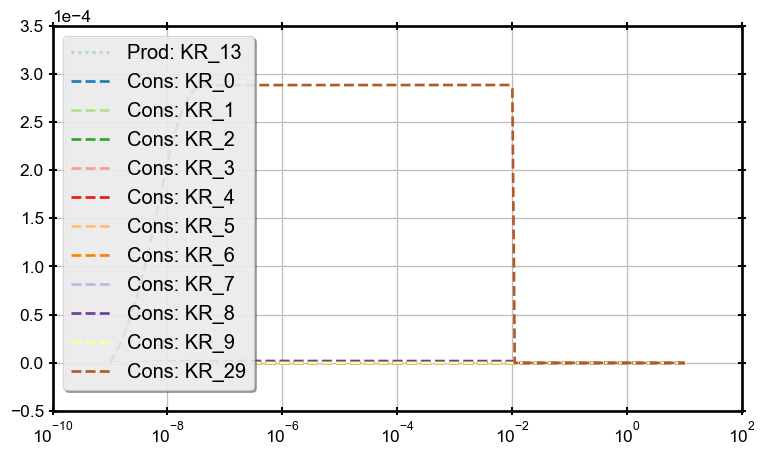

In [25]:
species = "e_aq"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in env.kreactions_involving_product(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in env.kreactions_involving_reactant(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    ax.legend()

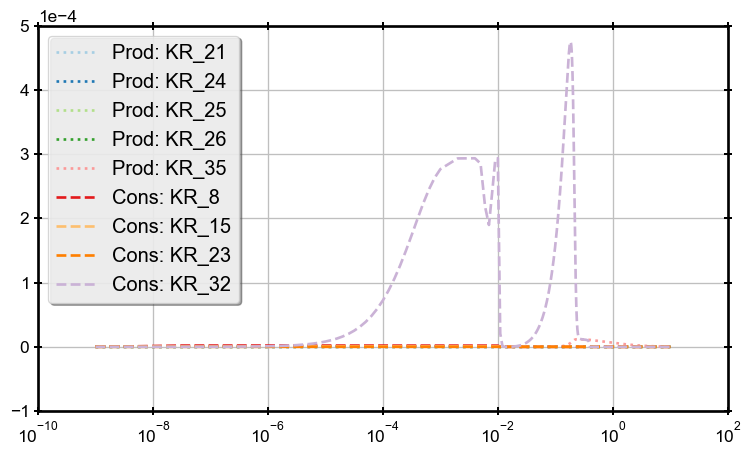

In [26]:
species = "O2"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in env.kreactions_involving_product(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in env.kreactions_involving_reactant(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    ax.legend()

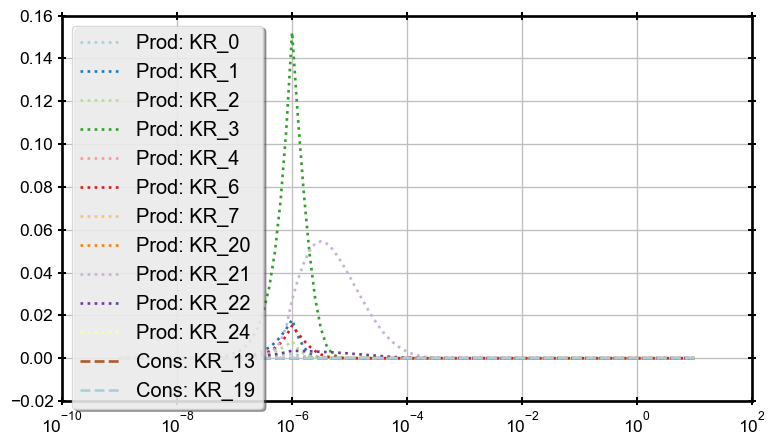

In [13]:
species = "OH_minus"
fig_man.set_brewer_map("Paired", "qualitative", 12)
with fig_man.open(f"reaction rates with {species}") as (fig, ax):
    for reaction in env.kreactions_involving_product(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Prod: {reaction.as_label()}", marker="", linestyle=":")
    for reaction in env.kreactions_involving_reactant(species):
        ax.semilogx(df.index, df[reaction.as_label()], label=f"Cons: {reaction.as_label()}", marker="", linestyle="--")
    ax.legend()

### Acid/Base

In [23]:
part = env.reactions.acid_base[2].compute_partition(1, 1e-7)
1/ (part.dHA / part.dA)

125.89254117941663

## Debug Enzimatic reactions

Enzi matrices:  
1. Ez_substrate VECTOR ==> substrate selection  
1. Ez_enzyme    VECTOR ==> Enzyme selection  
1. Ez_kmki      MATRIX ==> Line 0: K micha, Line 1: k_value 

Error is 
> Mismatch dimensions  
> Line: beta = np.matmul(Enzi[2][0, :] * Enzi[2][1, :], Enzi[0])

In [10]:
y0[10] = 4

In [14]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y0, Enzi[0])
KK = np.prod(Enzi[2], axis=0)

array([72820000.])

In [20]:
Enzi[2][1,:] * E * S 

array([21184000.])

In [21]:
MM = Enzi[2][1, :] * E * S / (Enzi[2][0, :] + S)
MM

array([4153725.49019608])

In [22]:
np.matmul(Enzi[0], MM)

array([      0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        , 4153725.49019608,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ,       0.        ,
             0.        ,       0.        ])

 ## Debug Jacobian

In [15]:
y0.shape

(29,)

In [19]:
y = np.array(np.arange(2,31))
for sp in env.species:
    print(f"{sp.index:02d}) {sp.label} {' '*(15-len(sp.label))} = {y[sp.index]:.2g}")

00) H2O              = 2
01) catalase         = 3
02) Fe_plus_plus     = 4
03) GSH              = 5
04) RH               = 6
05) unsat_lipid      = 7
06) H_plus           = 8
07) OH_minus         = 9
08) OH_r             = 10
09) O_r_minus        = 11
10) H2O2             = 12
11) HO2_minus        = 13
12) HO2_r            = 14
13) O2_r_minus       = 15
14) e_aq             = 16
15) H_r              = 17
16) H2               = 18
17) O2               = 19
18) O2_minus_minus   = 20
19) O3_minus         = 21
20) Fe_plus_plus_plus  = 22
21) HO_r             = 23
22) RH_r             = 24
23) R_r              = 25
24) ROO_r            = 26
25) trash            = 27
26) ROH              = 28
27) RO               = 29
28) ROOH             = 30


In [22]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
res = np.prod(res, axis=1).T * ki_mat[0] 
res.shape
#matprint(np.matmul(ki_mat[1], res.T))

(29, 38)

In [ ]:
res = np.nan_to_num(np.einsum("j, jikl -> ikl ", y, ki_mat[3]), nan=1)
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    matprint(res[:,:,sp.index])
    print()

e_aq
 2  1  
22  1  
12  1  
 5  1  
 6  1  
 3  1  
 7  1  
 8  1  
14  1  
10  1  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  
 0  0  



In [ ]:
for sp in env.iter_species():
    if sp.label != "e_aq":
        continue
    print(sp.label)
    for _ in range(ki_mat[3].shape[2]):
        matprint(ki_mat[3][:,:,_,sp.index])
        print()

e_aq
1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  2  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0

## Enzimatic contrib

In [66]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
np.multiply(Enzi[0], JEnzi[None,:])

array([[    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [33946.73970048],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ],
       [    0.        ]])

In [41]:
E = np.matmul(y0, Enzi[1])
S = np.matmul(y, Enzi[0]) + Enzi[2][0,:]
JEnzi = np.prod(Enzi[2], axis=0) * E / S / S # Vector...
JEnzi = np.multiply(Enzi[0], JEnzi)
JEnzi = np.matmul(Enzi[3], JEnzi.T)
print(JEnzi.shape)
matprint(JEnzi)

(29, 29)
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67893.5  0

In [57]:
Jab = ab_mat[0] + ab_mat[2].sum(axis=1)
matprint(np.multiply(JEnzi, Jab[None,:]))

0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0         0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  
0  0  0  0  0  0  0  0  0  0  -67892.1  0  0  0  0

In [58]:
ab_mat[0] + ab_mat[2].sum(axis=1)

array([1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       9.99987411e-01, 1.25890956e-05, 9.99980048e-01, 1.99522251e-05,
       7.88068385e-03, 9.92119316e-01, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00])

In [61]:
ab_mat[2]

array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [9.99987411e-01, 0.00000000e+00, 0.00000000e+00],
       [1.25890956e-05, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 9.99980048e-01, 0.00000000e+00],
       [0.00000000e+00, 1.99522251e-05, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 7.88068385e-03],
       [0.00000000e+00, 0.00000000e+00, 9.92119316e-01],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000